# Rainfall Forecasting for KP and Balochistan (1981–2025)
**Dataset:** Citywise Pakistan Rainfall (Kaggle) – rainfall in mm for every 10-day period since 1981 (CHIRPS satellite + station blend).

**Goal:** Use rainfall up to **this month** to forecast the rainfall of **next month**, for **Khyber Pakhtunkhwa (KP)** and **Balochistan**.

**Models:** Climatology (the normal for that month), "same as last month", Linear Regression, Random Forest, XGBoost, SARIMA and LSTM (SARIMA vs LSTM is the comparison of Paper 9).

## Step 1: Load the data

In [4]:
import glob, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error
warnings.filterwarnings('ignore')

f = [p for p in glob.glob('/kaggle/input/**/*.csv', recursive=True) if 'rain' in p.lower()]
print(f)
raw = pd.read_csv(f[0])
print(raw.shape)
raw.head()

['/kaggle/input/datasets/abdullahimranr2/citywise-pakistan-rainfall-by-qtr-19812025/ABD_Rainfall_1981_2025_PAK.csv']
(56176, 9)


,Date,PCODE,Country,Rainfall - (MM),Province,City,Year,Month,Quarter
0,01-01-81,PK2,Pakistan,6.0,Balochistan,Balochistan,1981.0,January,Q3
1,11-01-81,PK2,Pakistan,6.0,Balochistan,Balochistan,1981.0,January,Q3
2,21-01-81,PK2,Pakistan,9.0,Balochistan,Balochistan,1981.0,January,Q3
3,01-02-81,PK2,Pakistan,15.0,Balochistan,Balochistan,1981.0,February,Q3
4,11-02-81,PK2,Pakistan,5.0,Balochistan,Balochistan,1981.0,February,Q3


## Step 2: Clean the data
One junk row is removed. KP (PK5) has **two readings for every date**, so we take their average. Then we add the 10-day values into **monthly** totals.

In [5]:
d = raw.dropna(subset=['Year']).copy()
d['date'] = pd.to_datetime(d['Date'], format='%d-%m-%y')
d = d.rename(columns={'Rainfall - (MM)': 'rain'})
print('Date range:', d.date.min().date(), 'to', d.date.max().date())

series = {}
for code_, name in [('PK5', 'KP'), ('PK2', 'Balochistan')]:
    s = d[d.PCODE == code_].groupby('date').rain.mean()      # average the two KP readings
    m = s.resample('MS').sum()                               # 10-day -> monthly total
    m = m[:'2025-07-01']                                     # 2025 is only complete up to July
    series[name] = m
    print(name, 'months:', len(m), '| average month:', round(m.mean(), 1), 'mm | wettest month:', round(m.max(), 1), 'mm on', m.idxmax().date())

Date range: 1981-01-01 to 2025-07-21
KP months: 535 | average month: 46.0 mm | wettest month: 161.0 mm on 2010-08-01
Balochistan months: 535 | average month: 11.4 mm | wettest month: 118.0 mm on 2022-07-01


## Step 3: What does a normal year look like?

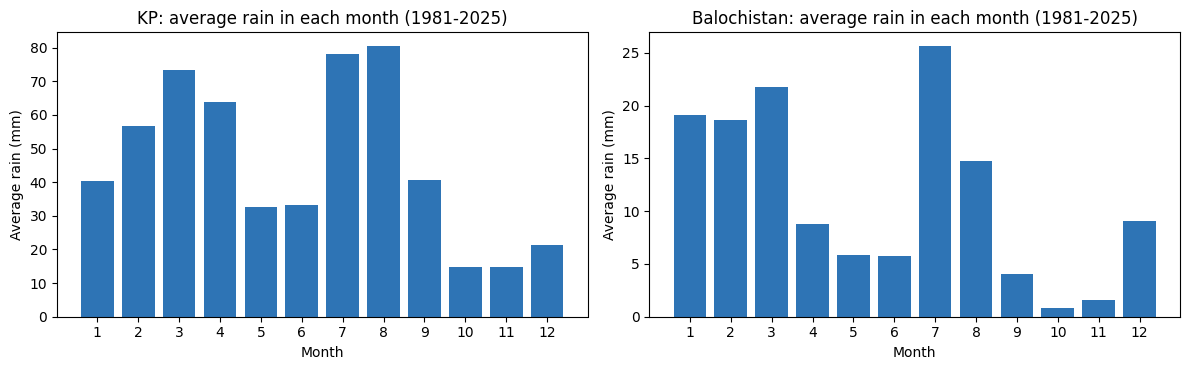

In [6]:
fig, axs = plt.subplots(1, 2, figsize=(12, 3.8))
for ax, (name, m) in zip(axs, series.items()):
    clim = m.groupby(m.index.month).mean()
    ax.bar(clim.index, clim.values, color='#2E74B5')
    ax.set_xticks(range(1, 13)); ax.set_xlabel('Month'); ax.set_ylabel('Average rain (mm)')
    ax.set_title(name + ': average rain in each month (1981-2025)')
plt.tight_layout(); plt.show()

## Step 4: Train and test split (by time)
The computer **studies 1981–2014** and is **tested on 2015–July 2025**. For every month it must forecast the **next month**.

In [7]:
def make_table(m):
    df = pd.DataFrame({'rain': m})
    for k in (1, 2, 3, 12):
        df[f'lag{k}'] = m.shift(k)
    df['month'] = df.index.month
    df['sin'] = np.sin(2*np.pi*df.month/12); df['cos'] = np.cos(2*np.pi*df.month/12)
    df['y'] = m.shift(-1)                      # ANSWER = next month
    df['target_month'] = (df.index + pd.offsets.MonthBegin(1)).month
    df['sin_t'] = np.sin(2*np.pi*df.target_month/12); df['cos_t'] = np.cos(2*np.pi*df.target_month/12)
    return df.dropna(subset=['lag12', 'y'])

FEATS = ['rain', 'lag1', 'lag2', 'lag3', 'lag12', 'sin_t', 'cos_t']
SPLIT = '2014-12-01'
tables = {n: make_table(m) for n, m in series.items()}
for n, t in tables.items():
    print(n, 'study months:', (t.index <= SPLIT).sum(), '| test months:', (t.index > SPLIT).sum())

KP study months: 396 | test months: 126
Balochistan study months: 396 | test months: 126


## Step 5: Train the models and compare

In [8]:
try:
    from xgboost import XGBRegressor
    HAS_XGB = True
except Exception:
    HAS_XGB = False
try:
    from statsmodels.tsa.statespace.sarimax import SARIMAX
    HAS_SARIMA = True
except Exception:
    HAS_SARIMA = False
try:
    import tensorflow as tf
    from tensorflow.keras import layers, callbacks
    HAS_TF = True
except Exception:
    HAS_TF = False
print('XGBoost:', HAS_XGB, '| SARIMA:', HAS_SARIMA, '| LSTM:', HAS_TF)

def score(y, p):
    return dict(R2=r2_score(y, p), RMSE=mean_squared_error(y, p)**0.5, MAE=mean_absolute_error(y, p))

results, preds = {}, {}
for name, m in series.items():
    t = tables[name]
    tr, te = t[t.index <= SPLIT], t[t.index > SPLIT]
    P = {}
    # 1. Climatology = normal rain of that month in the study years
    clim = tr.groupby('target_month').y.mean()
    P['Climatology (normal)'] = te.target_month.map(clim).values
    # 2. Same as this month
    P['Same as this month'] = te['rain'].values
    # 3. Linear / RF / XGBoost
    P['Linear Regression'] = LinearRegression().fit(tr[FEATS], tr.y).predict(te[FEATS])
    P['Random Forest'] = RandomForestRegressor(300, random_state=0, n_jobs=-1).fit(tr[FEATS], tr.y).predict(te[FEATS])
    if HAS_XGB:
        P['XGBoost'] = XGBRegressor(n_estimators=300, max_depth=3, learning_rate=0.05, random_state=0).fit(tr[FEATS], tr.y).predict(te[FEATS])
    # 4. SARIMA (seasonal model), one-step-ahead forecasts on the test months
    if HAS_SARIMA:
        mtr = m[:SPLIT]
        res = SARIMAX(mtr, order=(1, 0, 1), seasonal_order=(1, 1, 1, 12)).fit(disp=False)
        ext = res.append(m[mtr.index[-1] + pd.offsets.MonthBegin(1):], refit=False)
        pr = ext.get_prediction(start=mtr.index[-1] + pd.offsets.MonthBegin(1)).predicted_mean.clip(lower=0)
        P['SARIMA'] = pr.reindex(te.index + pd.offsets.MonthBegin(1)).values
        P['SARIMA'] = np.where(np.isnan(P['SARIMA']), np.nanmean(P['SARIMA']), P['SARIMA'])
    # 5. LSTM on the last 12 months
    if HAS_TF:
        tf.random.set_seed(0); np.random.seed(0)
        sc = StandardScaler().fit(m[:SPLIT].values.reshape(-1, 1))
        z = sc.transform(m.values.reshape(-1, 1)).ravel()
        idx = {d_: i for i, d_ in enumerate(m.index)}
        def win(index):
            X = np.array([z[idx[d_]-11: idx[d_]+1] for d_ in index if idx[d_] >= 11])
            return X[..., None]
        trw = tr[[i in idx and idx[i] >= 11 for i in tr.index]]
        Xtr, ytr = win(trw.index), sc.transform(trw.y.values.reshape(-1, 1)).ravel()
        Xte = win(te.index)
        model = tf.keras.Sequential([layers.Input((12, 1)), layers.LSTM(32), layers.Dense(1)])
        model.compile(optimizer='adam', loss='mse')
        model.fit(Xtr, ytr, epochs=60, batch_size=16, validation_split=0.15, verbose=0,
                  callbacks=[callbacks.EarlyStopping(patience=8, restore_best_weights=True)])
        P['LSTM'] = np.clip(sc.inverse_transform(model.predict(Xte, verbose=0)).ravel(), 0, None)
    preds[name] = (te, P)
    results[name] = pd.DataFrame({k: score(te.y.values, v) for k, v in P.items()}).T.round(3)
    print('\n' + name); print(results[name])

XGBoost: True | SARIMA: True | LSTM: True


2026-10-19 06:45:04.626889: E external/local_xla/xla/stream_executor/cuda/cuda_platform.cc:51] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: UNKNOWN ERROR (303)



KP
                         R2    RMSE     MAE
Climatology (normal)  0.475  25.209  19.175
Same as this month   -0.357  40.538  30.329
Linear Regression     0.272  29.693  22.834
Random Forest         0.423  26.426  19.406
XGBoost               0.371  27.586  20.376
SARIMA                0.520  24.101  18.301
LSTM                  0.271  29.709  22.312

Balochistan
                         R2    RMSE     MAE
Climatology (normal)  0.293  14.010   7.703
Same as this month   -0.579  20.941  13.317
Linear Regression     0.067  16.094  10.090
Random Forest         0.290  14.038   8.158
XGBoost               0.256  14.375   8.527
SARIMA                0.343  13.503   7.640
LSTM                  0.102  15.796   9.153


## Step 6: Score chart (R² – higher is better)

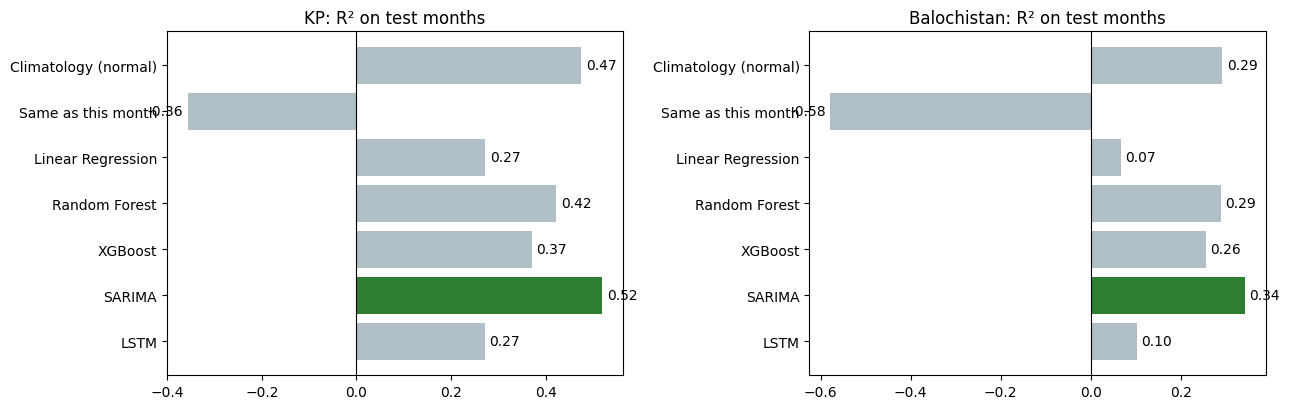

In [9]:
fig, axs = plt.subplots(1, 2, figsize=(13, 4.2), sharex=False)
for ax, (name, r) in zip(axs, results.items()):
    cols = ['#2E7D32' if i == r.R2.idxmax() else '#B0BEC5' for i in r.index]
    ax.barh(r.index[::-1], r.R2.values[::-1], color=cols[::-1])
    for y_, v in enumerate(r.R2.values[::-1]):
        ax.text(v + (0.01 if v >= 0 else -0.01), y_, f'{v:.2f}', va='center', ha='left' if v >= 0 else 'right')
    ax.axvline(0, color='k', lw=0.8); ax.set_title(name + ': R² on test months')
plt.tight_layout(); plt.show()

## Step 7: Real rain vs predicted rain (test years)

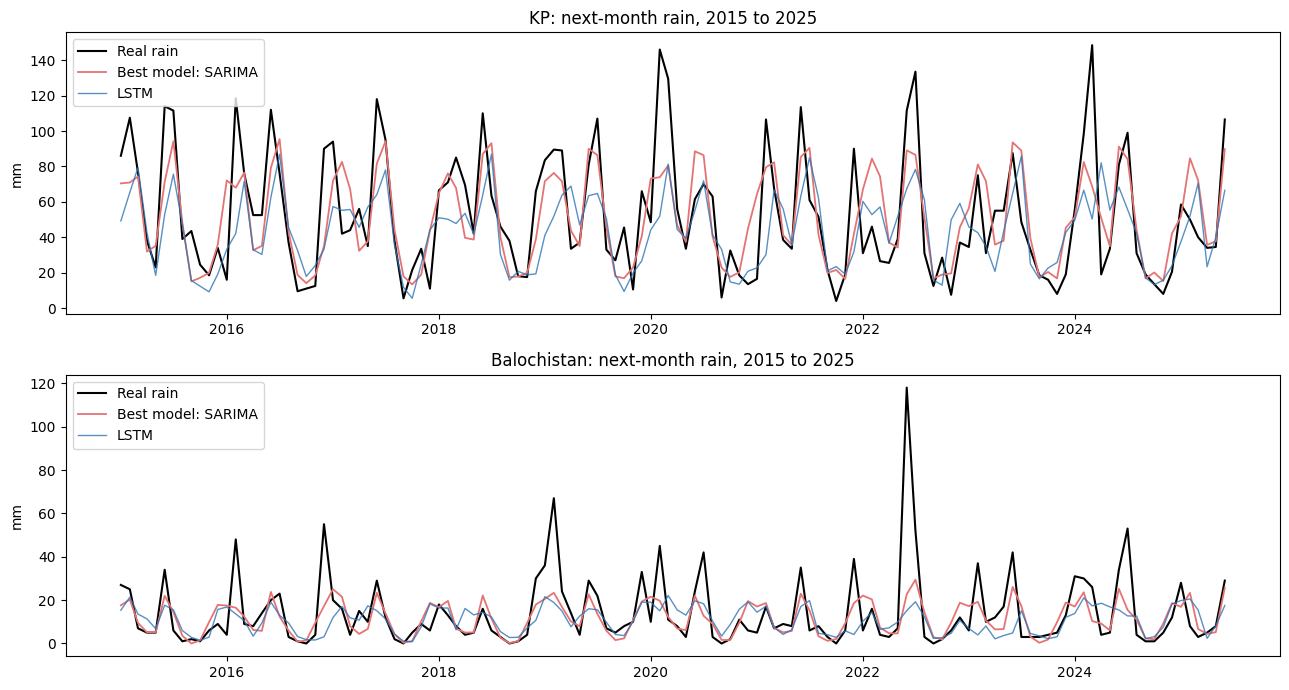

In [10]:
fig, axs = plt.subplots(2, 1, figsize=(13, 7))
for ax, (name, (te, P)) in zip(axs, preds.items()):
    best = results[name].R2.idxmax()
    ax.plot(te.index, te.y.values, color='black', lw=1.5, label='Real rain')
    ax.plot(te.index, P[best], color='#E57373', lw=1.3, label='Best model: ' + best)
    if 'LSTM' in P: ax.plot(te.index, P['LSTM'], color='#2E74B5', lw=1, alpha=.8, label='LSTM')
    ax.set_title(name + ': next-month rain, 2015 to 2025'); ax.set_ylabel('mm'); ax.legend(loc='upper left')
plt.tight_layout(); plt.show()

## Step 8: Can the models see the BIG rain months?
We take the 5 wettest months in the test years and compare the real rain with what the best model and the normal (climatology) said.

In [11]:
rows = []
for name, (te, P) in preds.items():
    best = results[name].R2.idxmax()
    top = te.y.nlargest(5).index
    for d_ in top:
        i = list(te.index).index(d_)
        rows.append([name, (d_ + pd.offsets.MonthBegin(1)).strftime('%b %Y'), round(te.y[d_], 1),
                     round(float(P['Climatology (normal)'][i]), 1), round(float(P[best][i]), 1)])
big = pd.DataFrame(rows, columns=['Region', 'Month', 'Real rain (mm)', 'Normal (mm)', 'Best model (mm)'])
big

,Region,Month,Real rain (mm),Normal (mm),Best model (mm)
0,KP,Apr 2024,148.5,60.9,68.7
1,KP,Mar 2020,146.0,68.2,73.9
2,KP,Aug 2022,133.5,79.0,86.5
3,KP,Apr 2020,129.5,60.9,80.5
4,KP,Mar 2016,118.5,68.2,67.9
5,Balochistan,Jul 2022,118.0,21.9,22.7
6,Balochistan,Mar 2019,67.0,19.2,23.4
7,Balochistan,Jan 2017,55.0,17.8,17.2
8,Balochistan,Aug 2024,53.0,12.7,15.5
9,Balochistan,Aug 2022,52.0,12.7,29.4


## Step 9: Rainfall in the monsoon months only (Jul–Sep)

In [12]:
rows = []
for name, (te, P) in preds.items():
    mask = te.target_month.isin([7, 8, 9]).values
    for k, v in P.items():
        rows.append([name, k, round(r2_score(te.y.values[mask], v[mask]), 3), round(mean_absolute_error(te.y.values[mask], v[mask]), 1)])
pd.DataFrame(rows, columns=['Region', 'Model', 'R2 (Jul-Sep)', 'MAE mm (Jul-Sep)'])

,Region,Model,R2 (Jul-Sep),MAE mm (Jul-Sep)
0,KP,Climatology (normal),0.324,21.0
1,KP,Same as this month,-1.819,45.6
2,KP,Linear Regression,-0.368,29.4
3,KP,Random Forest,0.149,21.6
4,KP,XGBoost,-0.048,24.0
5,KP,SARIMA,0.482,19.4
6,KP,LSTM,-0.021,26.8
7,Balochistan,Climatology (normal),0.137,11.7
8,Balochistan,Same as this month,-0.931,24.3
9,Balochistan,Linear Regression,-0.128,16.0


## Conclusion
- We used 45 years of rainfall (1981–2025) to forecast **next month's rain** in **KP** and **Balochistan**.
- Rain is hard to predict from its own history: the simple **"normal for that month" (climatology)** is very hard to beat. Models that only see past rain add little.
- The very wet months (for example, Balochistan July 2022) are far above the normal, and the models predict values near the normal, so they miss the biggest events.
- **Limitations:** only rainfall (no temperature, humidity, soil or satellite images), monthly totals, one average value per province.
- **Link to my thesis:** rainfall history alone cannot warn of a flash flood. My thesis needs **short-term satellite rainfall (GPM IMERG) + weather + terrain** for hours-ahead warnings in KP and Balochistan.